
<div dir="rtl" style="text-align: right;">

# منصة TechStudent AI

## مولد خارطة التعلم الذكية (Learning Roadmap Generator)

### مشروع ذكاء اصطناعي ونظام توصية

**هدف المشروع:**

يهدف هذا المشروع إلى بناء نظام ذكي يساعد الطالب على إنشاء خارطة تعلم مناسبة بناءً على المجال أو المهارة التي يرغب في تعلمها.

يعتمد النظام على تحليل بيانات الدورات والمواد التعليمية والمسارات المتاحة، ثم يقوم باختيار المحتوى الأكثر ارتباطًا بهدف المستخدم وترتيبه في خطوات مقترحة.

**مراحل المشروع:**

1. تحميل بيانات الدورات والمسارات التعليمية.
2. فهم البيانات وفحصها.
3. تنظيف البيانات.
4. التحليل الاستكشافي للبيانات (EDA).
5. تجهيز البيانات لنظام التوصية.
6. بناء نظام توصية باستخدام TF-IDF وCosine Similarity.
7. إنشاء خارطة تعلم.
8. اختبار النظام بمدخلات جديدة.
9. حفظ النظام لاستخدامه لاحقًا في واجهة الويب.

</div>


In [1]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import joblib

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# تحديد مسارات البيانات بشكل متوافق مع تشغيل الـNotebook من مجلد notebooks

from pathlib import Path

BASE_DIR = Path.cwd().resolve()

possible_data_dirs = [
    BASE_DIR.parent / "data",
    BASE_DIR / "data",
]

DATA_DIR = next((p for p in possible_data_dirs if p.exists()), BASE_DIR.parent / "data")

courses_path = DATA_DIR / "Courses_and_Learning_Material.csv"
roadmap_path = DATA_DIR / "Learning_Pathway_Index.csv"

print("Data directory:", DATA_DIR)
print("Courses file exists:", courses_path.exists())
print("Roadmap file exists:", roadmap_path.exists())

Data directory: D:\سنة ثالثة\ترم اول\مبادئ الذكاء الاصطناعي\عملي\TechStudent_AI_Platform\data
Courses file exists: True
Roadmap file exists: True



<div dir="rtl" style="text-align: right;">

## تحميل مجموعة البيانات (Data Loading)

في هذه المرحلة نقوم بتحميل مجموعتي البيانات المستخدمتين في المشروع:

- بيانات الدورات والمواد التعليمية.
- بيانات المسارات التعليمية.

وسيتم استخدامهما لاحقًا لبناء نظام التوصية وإنشاء خارطة تعلم مناسبة.

</div>


In [3]:
courses_df = pd.read_csv(courses_path)
roadmap_df = pd.read_csv(roadmap_path)

print("Courses Dataset Shape:", courses_df.shape)
print("Roadmap Dataset Shape:", roadmap_df.shape)
print("\nData loaded successfully!")

Courses Dataset Shape: (34, 9)
Roadmap Dataset Shape: (1382, 10)

Data loaded successfully!


In [4]:

print("Courses Dataset Preview:")
display(courses_df.head())

print("\nRoadmap Dataset Preview:")
display(roadmap_df.head())


Courses Dataset Preview:


,Module_Code,Source,Course_Level,Duration,Prerequisites,Prework,Course_Learning_Material,Course_Learning_Material_Link,Type_Free_Paid
0,CLMML00,Google Developers,Beginners,70 minutes,No,No,Introduction to Machine Learning,https://developers.google.com/machine-learning...,Free
1,CLMML01,Google Developers,Beginners to Intermediate,NaN,"Yes, a handful",Yes,Machine Learning Crash Course (Foundation),https://developers.google.com/machine-learning...,Free
2,CLMML02,Google Developers,Beginners to Intermediate,45 minutes,No,No,Problem Framing (ML related),https://developers.google.com/machine-learning...,Free
3,CLMML03,Google Developers,Beginners to Intermediate,NaN,No,No,Data Preparation and Feature Engineering in ML,https://developers.google.com/machine-learning...,Free
4,CLMML04,Google Developers,Beginners to Intermediate,NaN,Yes,No,Testing and Debugging,https://developers.google.com/machine-learning...,Free



Roadmap Dataset Preview:


,Module_Code,Course_Learning_Material,Source,Course_Level,Type_Free_Paid,Module,Duration,Difficulty_Level,Keywords_Tags_Skills_Interests_Categories,Links
0,CLMML00,Introduction to Machine Learning,Google Developers,Beginner,Free,Introduction to Machine Learning,20.0 minutes,Easy,machine learning,https://developers.google.com/machine-learning...
1,CLMML00,Introduction to Machine Learning,Google Developers,Beginner,Free,What is Machine Learning,20.0 minutes,Easy,machine learning,https://developers.google.com/machine-learning...
2,CLMML00,Introduction to Machine Learning,Google Developers,Beginner,Free,Supervised Learning,20.0 minutes,Medium,supervised learning,https://developers.google.com/machine-learning...
3,CLMML00,Introduction to Machine Learning,Google Developers,Beginner,Free,Test your understanding,10.0 minutes,Easy,machine learning test,https://developers.google.com/machine-learning...
4,CLMML01,Machine Learning Crash Course (Foundation),Google Developers,Intermediate,Free,Introduction to ML,3.0 minutes,Easy,machine learning,https://developers.google.com/machine-learning...


In [5]:

print("Courses Dataset Shape:", courses_df.shape)
print("Roadmap Dataset Shape:", roadmap_df.shape)


Courses Dataset Shape: (34, 9)
Roadmap Dataset Shape: (1382, 10)


In [6]:

print("Courses Dataset Columns:")
print(courses_df.columns.tolist())

print("\nRoadmap Dataset Columns:")
print(roadmap_df.columns.tolist())


Courses Dataset Columns:
['Module_Code', 'Source', 'Course_Level', 'Duration', 'Prerequisites', 'Prework', 'Course_Learning_Material', 'Course_Learning_Material_Link', 'Type_Free_Paid']

Roadmap Dataset Columns:
['Module_Code', 'Course_Learning_Material', 'Source', 'Course_Level', 'Type_Free_Paid', 'Module', 'Duration', 'Difficulty_Level', 'Keywords_Tags_Skills_Interests_Categories', 'Links']


In [7]:

print("Courses Dataset Information:")
courses_df.info()

print("\n" + "=" * 60)

print("\nRoadmap Dataset Information:")
roadmap_df.info()


Courses Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   Module_Code                    34 non-null     str  
 1   Source                         34 non-null     str  
 2   Course_Level                   34 non-null     str  
 3   Duration                       16 non-null     str  
 4   Prerequisites                  34 non-null     str  
 5   Prework                        34 non-null     str  
 6   Course_Learning_Material       34 non-null     str  
 7   Course_Learning_Material_Link  34 non-null     str  
 8   Type_Free_Paid                 34 non-null     str  
dtypes: str(9)
memory usage: 2.5 KB


Roadmap Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1382 entries, 0 to 1381
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype
---  ----

In [8]:

print("Missing Values in Courses Dataset:")
display(courses_df.isnull().sum().to_frame("Missing Values"))

print("\nMissing Values in Roadmap Dataset:")
display(roadmap_df.isnull().sum().to_frame("Missing Values"))


Missing Values in Courses Dataset:


,Missing Values
Module_Code,0
Source,0
Course_Level,0
Duration,18
Prerequisites,0
Prework,0
Course_Learning_Material,0
Course_Learning_Material_Link,0
Type_Free_Paid,0



Missing Values in Roadmap Dataset:


,Missing Values
Module_Code,0
Course_Learning_Material,0
Source,0
Course_Level,0
Type_Free_Paid,0
Module,0
Duration,61
Difficulty_Level,1
Keywords_Tags_Skills_Interests_Categories,0
Links,9



<div dir="rtl" style="text-align: right;">

## فحص الصفوف المكررة

في هذه الخطوة يتم فحص مجموعتي البيانات لمعرفة عدد الصفوف المكررة، لأن تكرار السجلات قد يؤدي إلى تكرار نفس المحتوى داخل نتائج التوصية.

</div>


In [9]:

print("Duplicate Rows in Courses Dataset:", courses_df.duplicated().sum())
print("Duplicate Rows in Roadmap Dataset:", roadmap_df.duplicated().sum())


Duplicate Rows in Courses Dataset: 0
Duplicate Rows in Roadmap Dataset: 0



<div dir="rtl" style="text-align: right;">

# تنظيف البيانات

بعد فحص البيانات، نقوم بإزالة الصفوف المكررة ومعالجة القيم المفقودة وتنظيف النصوص من المسافات الزائدة، حتى تصبح البيانات مناسبة للتحليل وبناء نظام التوصية.

</div>


In [10]:

courses_df = courses_df.drop_duplicates().copy()
roadmap_df = roadmap_df.drop_duplicates().copy()

print("Courses Dataset Shape After Removing Duplicates:", courses_df.shape)
print("Roadmap Dataset Shape After Removing Duplicates:", roadmap_df.shape)


Courses Dataset Shape After Removing Duplicates: (34, 9)
Roadmap Dataset Shape After Removing Duplicates: (1382, 10)


In [11]:
# تنظيف بيانات الدورات والمسارات بطريقة آمنة

def clean_dataframe(df):
    df = df.copy()

    # تنظيف الأعمدة النصية
    for column in df.select_dtypes(include=["object", "string"]).columns:
        df[column] = df[column].fillna("Unknown").astype(str).str.strip()

    # تنظيف الأعمدة الرقمية فقط
    for column in df.select_dtypes(include=[np.number]).columns:
        median_value = df[column].median()
        if pd.isna(median_value):
            median_value = 0
        df[column] = df[column].fillna(median_value)

    return df

courses_df = clean_dataframe(courses_df)
roadmap_df = clean_dataframe(roadmap_df)

print("Data cleaning completed successfully!")
print("Remaining missing values in Courses:", courses_df.isnull().sum().sum())
print("Remaining missing values in Roadmap:", roadmap_df.isnull().sum().sum())

Data cleaning completed successfully!
Remaining missing values in Courses: 0
Remaining missing values in Roadmap: 0


In [12]:

print("Remaining Missing Values in Courses Dataset:", courses_df.isnull().sum().sum())
print("Remaining Missing Values in Roadmap Dataset:", roadmap_df.isnull().sum().sum())

print("Duplicate Rows in Courses Dataset:", courses_df.duplicated().sum())
print("Duplicate Rows in Roadmap Dataset:", roadmap_df.duplicated().sum())


Remaining Missing Values in Courses Dataset: 0
Remaining Missing Values in Roadmap Dataset: 0
Duplicate Rows in Courses Dataset: 0
Duplicate Rows in Roadmap Dataset: 0



<div dir="rtl" style="text-align: right;">

## التحليل الاستكشافي للبيانات (EDA)

في هذه المرحلة يتم تحليل البيانات لفهم طبيعة المحتوى التعليمي والمسارات الموجودة، وذلك من خلال معرفة عدد السجلات، وعدد القيم الفريدة في الأعمدة، وتوزيع بعض المجالات أو المستويات التعليمية.

يساعد هذا التحليل على فهم البيانات قبل بناء نظام التوصية.

</div>


In [13]:

print("Number of Courses Records:", len(courses_df))
print("Number of Roadmap Records:", len(roadmap_df))

print("\nNumber of Courses Columns:", len(courses_df.columns))
print("Number of Roadmap Columns:", len(roadmap_df.columns))


Number of Courses Records: 34
Number of Roadmap Records: 1382

Number of Courses Columns: 9
Number of Roadmap Columns: 10


In [14]:

print("Unique Values in Courses Dataset Text Columns:\n")

for column in courses_df.select_dtypes(include="object").columns:
    print(f"{column}: {courses_df[column].nunique()}")


Unique Values in Courses Dataset Text Columns:

Module_Code: 33
Source: 5
Course_Level: 7
Duration: 13
Prerequisites: 3
Prework: 3
Course_Learning_Material: 34
Course_Learning_Material_Link: 34
Type_Free_Paid: 2


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17304\1347171761.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in courses_df.select_dtypes(include="object").columns:


In [15]:

print("Unique Values in Roadmap Dataset Text Columns:\n")

for column in roadmap_df.select_dtypes(include="object").columns:
    print(f"{column}: {roadmap_df[column].nunique()}")


Unique Values in Roadmap Dataset Text Columns:

Module_Code: 26
Course_Learning_Material: 20
Source: 4
Course_Level: 3
Type_Free_Paid: 2
Module: 1339
Duration: 107
Difficulty_Level: 4
Keywords_Tags_Skills_Interests_Categories: 370
Links: 1244


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17304\1659501904.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in roadmap_df.select_dtypes(include="object").columns:


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17304\2358420053.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = courses_df.select_dtypes(include="object").columns.tolist()


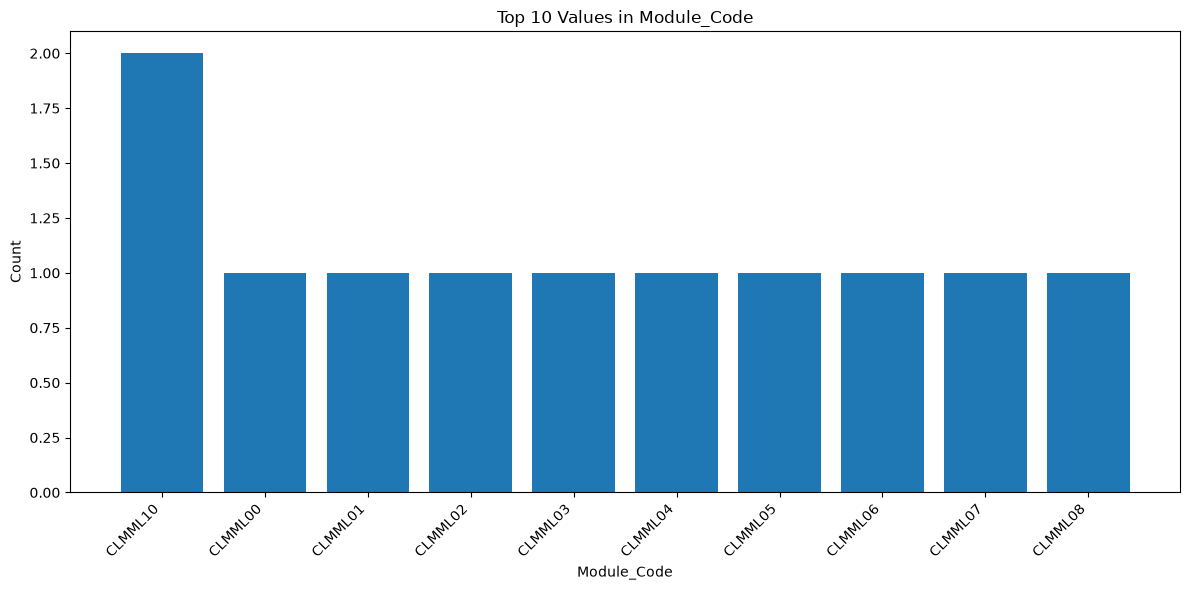

In [16]:

# اختيار أول عمود نصي مناسب للرسم

text_columns = courses_df.select_dtypes(include="object").columns.tolist()

if text_columns:
    selected_column = text_columns[0]
    top_values = courses_df[selected_column].value_counts().head(10)

    plt.figure(figsize=(12, 6))
    plt.bar(top_values.index.astype(str), top_values.values)

    plt.title(f"Top 10 Values in {selected_column}")
    plt.xlabel(selected_column)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No text columns available for visualization.")


In [19]:
# الإحصائيات الوصفية للأعمدة المتاحة
courses_df.describe(include="all")

,Module_Code,Source,Course_Level,Duration,Prerequisites,Prework,Course_Learning_Material,Course_Learning_Material_Link,Type_Free_Paid
count,34,34,34,34,34,34,34,34,34
unique,33,5,7,13,3,3,34,34,2
top,CLMML10,Google Cloud Skills Boost,Beginners,Unknown,No,No,Introduction to Machine Learning,https://developers.google.com/machine-learning...,Free
freq,2,18,10,18,27,29,1,1,19



<div dir="rtl" style="text-align: right;">

## تجهيز البيانات لنظام التوصية (Data Preparation)

في هذه المرحلة يتم تجهيز المعلومات النصية لاستخدامها في بناء نظام التوصية.

يتم دمج الأعمدة النصية الموجودة في بيانات الدورات داخل وصف موحد لكل سجل، بحيث يستطيع النظام مقارنة هدف المستخدم مع المعلومات المتاحة عن الدورات والمواد التعليمية.

</div>


In [20]:

prepared_courses = courses_df.copy()

course_text_columns = prepared_courses.select_dtypes(include="object").columns.tolist()

print("Course Text Columns:")
print(course_text_columns)


Course Text Columns:
['Module_Code', 'Source', 'Course_Level', 'Duration', 'Prerequisites', 'Prework', 'Course_Learning_Material', 'Course_Learning_Material_Link', 'Type_Free_Paid']


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17304\2277396956.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  course_text_columns = prepared_courses.select_dtypes(include="object").columns.tolist()


In [21]:

prepared_courses["combined_features"] = (
    prepared_courses[course_text_columns]
    .astype(str)
    .agg(" ".join, axis=1)
)

prepared_courses[["combined_features"]].head()


,combined_features
0,CLMML00 Google Developers Beginners 70 minutes...
1,CLMML01 Google Developers Beginners to Interme...
2,CLMML02 Google Developers Beginners to Interme...
3,CLMML03 Google Developers Beginners to Interme...
4,CLMML04 Google Developers Beginners to Interme...


In [22]:

prepared_roadmap = roadmap_df.copy()

roadmap_text_columns = prepared_roadmap.select_dtypes(include="object").columns.tolist()

print("Roadmap Text Columns:")
print(roadmap_text_columns)


Roadmap Text Columns:
['Module_Code', 'Course_Learning_Material', 'Source', 'Course_Level', 'Type_Free_Paid', 'Module', 'Duration', 'Difficulty_Level', 'Keywords_Tags_Skills_Interests_Categories', 'Links']


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_17304\2198714412.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  roadmap_text_columns = prepared_roadmap.select_dtypes(include="object").columns.tolist()


In [23]:

prepared_roadmap["combined_features"] = (
    prepared_roadmap[roadmap_text_columns]
    .astype(str)
    .agg(" ".join, axis=1)
)

prepared_roadmap[["combined_features"]].head()


,combined_features
0,CLMML00 Introduction to Machine Learning Googl...
1,CLMML00 Introduction to Machine Learning Googl...
2,CLMML00 Introduction to Machine Learning Googl...
3,CLMML00 Introduction to Machine Learning Googl...
4,CLMML01 Machine Learning Crash Course (Foundat...



<div dir="rtl" style="text-align: right;">

## بناء نظام الذكاء الاصطناعي للتوصية (Recommendation System)

في هذه المرحلة يتم بناء نظام توصية يعتمد على تحليل النصوص.

يتم استخدام تقنية **TF-IDF** لتحويل المعلومات النصية إلى تمثيل رقمي، ثم يتم استخدام **Cosine Similarity** لقياس مدى التشابه بين هدف المستخدم والمحتوى التعليمي.

كلما كانت درجة التشابه أعلى، كان المحتوى أكثر ارتباطًا بهدف المستخدم.

</div>


In [24]:

course_vectorizer = TfidfVectorizer(stop_words="english")

course_vectors = course_vectorizer.fit_transform(
    prepared_courses["combined_features"]
)

print("Course recommendation system prepared successfully!")
print("Course Vectors Shape:", course_vectors.shape)


Course recommendation system prepared successfully!
Course Vectors Shape: (34, 199)


In [25]:

roadmap_vectorizer = TfidfVectorizer(stop_words="english")

roadmap_vectors = roadmap_vectorizer.fit_transform(
    prepared_roadmap["combined_features"]
)

print("Learning pathway recommendation system prepared successfully!")
print("Roadmap Vectors Shape:", roadmap_vectors.shape)


Learning pathway recommendation system prepared successfully!
Roadmap Vectors Shape: (1382, 2421)


In [26]:

# عرض عدد الكلمات التي تعلمها كل نظام

print("Number of Course Features:", len(course_vectorizer.get_feature_names_out()))
print("Number of Roadmap Features:", len(roadmap_vectorizer.get_feature_names_out()))


Number of Course Features: 199
Number of Roadmap Features: 2421



<div dir="rtl" style="text-align: right;">

## إنشاء نظام التوصية بالدورات

في هذه المرحلة يتم إنشاء دالة تستقبل المجال أو المهارة التي يرغب المستخدم في تعلمها، ثم تقوم بحساب درجة التشابه مع جميع الدورات والمواد التعليمية وإرجاع أفضل النتائج.

</div>


In [27]:

def recommend_courses(user_interest, top_n=10):

    user_vector = course_vectorizer.transform([user_interest])

    similarity_scores = cosine_similarity(
        user_vector,
        course_vectors
    ).flatten()

    top_indices = similarity_scores.argsort()[::-1][:top_n]

    recommendations = prepared_courses.iloc[top_indices].copy()

    recommendations["Similarity Score"] = similarity_scores[top_indices]

    return recommendations



<div dir="rtl" style="text-align: right;">

## إنشاء نظام التوصية بالمسارات التعليمية

في هذه المرحلة يتم إنشاء دالة مشابهة للبحث عن أفضل المسارات التعليمية المرتبطة بهدف المستخدم.

</div>


In [28]:

def recommend_learning_path(user_interest, top_n=5):

    user_vector = roadmap_vectorizer.transform([user_interest])

    similarity_scores = cosine_similarity(
        user_vector,
        roadmap_vectors
    ).flatten()

    top_indices = similarity_scores.argsort()[::-1][:top_n]

    recommendations = prepared_roadmap.iloc[top_indices].copy()

    recommendations["Similarity Score"] = similarity_scores[top_indices]

    return recommendations



<div dir="rtl" style="text-align: right;">

## التنبؤ على بيانات جديدة (Making Recommendations)

في هذه المرحلة يتم إدخال هدف تعلم جديد، ثم يقوم النظام بتحليل الهدف وإرجاع أفضل المسارات التعليمية والدورات والمواد المرتبطة به.

</div>


In [29]:

user_interest = "Machine Learning"

recommended_paths = recommend_learning_path(
    user_interest,
    top_n=5
)

print("Recommended Learning Paths:")
display(
    recommended_paths.drop(
        columns=["combined_features"],
        errors="ignore"
    )
)


Recommended Learning Paths:


,Module_Code,Course_Learning_Material,Source,Course_Level,Type_Free_Paid,Module,Duration,Difficulty_Level,Keywords_Tags_Skills_Interests_Categories,Links,Similarity Score
1,CLMML00,Introduction to Machine Learning,Google Developers,Beginner,Free,What is Machine Learning,20.0 minutes,Easy,machine learning,https://developers.google.com/machine-learning...,0.466194
0,CLMML00,Introduction to Machine Learning,Google Developers,Beginner,Free,Introduction to Machine Learning,20.0 minutes,Easy,machine learning,https://developers.google.com/machine-learning...,0.459184
124,CLMML06,Machine Learning Advance Courses,Google Developers,Advanced,Free,Introduction,5.0 minutes,Easy,"Machine Learning, Advance Machine Learning, Re...",https://developers.google.com/machine-learning...,0.457057
782,CLMML11,Machine Learning Engineer Learning Path,Google Cloud Skill Boost,Advanced,Free during mentorship period,Machine Learning in Practice: Machine Learning...,5.0 minutes,Medium,"Machine Learning,Supervised learning,Linear Re...",https://www.cloudskillsboost.google/course_ses...,0.438718
783,CLMML11,Machine Learning Engineer Learning Path,Google Cloud Skill Boost,Advanced,Free during mentorship period,Machine Learning in Practice: Resources: Machi...,8.0 minutes,Medium,"Machine Learning,Supervised learning,Linear Re...",https://www.cloudskillsboost.google/course_ses...,0.430203


In [30]:

recommended_courses = recommend_courses(
    user_interest,
    top_n=10
)

print("Recommended Courses and Learning Materials:")
display(
    recommended_courses.drop(
        columns=["combined_features"],
        errors="ignore"
    )
)


Recommended Courses and Learning Materials:


,Module_Code,Source,Course_Level,Duration,Prerequisites,Prework,Course_Learning_Material,Course_Learning_Material_Link,Type_Free_Paid,Similarity Score
0,CLMML00,Google Developers,Beginners,70 minutes,No,No,Introduction to Machine Learning,https://developers.google.com/machine-learning...,Free,0.433916
15,CLMML12,Google Developers,Intermediate to Advanced,Unknown,Yes,Yes,Machine Learning Advance Courses,https://developers.google.com/machine-learning...,Free,0.369212
1,CLMML01,Google Developers,Beginners to Intermediate,Unknown,"Yes, a handful",Yes,Machine Learning Crash Course (Foundation),https://developers.google.com/machine-learning...,Free,0.316106
14,CLMML11,Google Cloud Skills Boost,Intermediate to Advanced,Unknown,Yes,Yes,Machine Learning Engineer Learning Path,https://www.cloudskillsboost.google/paths/17,Free,0.315020
8,CLMML08,Google Developers,Intermediate to Advanced,Unknown,No,No,Generative Adversarial Networks,https://developers.google.com/machine-learning...,Free,0.231462
7,CLMML07,Google Developers,Intermediate to Advanced,Unknown,No,No,Clustering,https://developers.google.com/machine-learning...,Free,0.226399
6,CLMML06,Google Developers,Intermediate to Advanced,Unknown,No,No,Recommendation Systems,https://developers.google.com/machine-learning...,Free,0.215268
3,CLMML03,Google Developers,Beginners to Intermediate,Unknown,No,No,Data Preparation and Feature Engineering in ML,https://developers.google.com/machine-learning...,Free,0.210441
10,CLMML10,Google Developers,Intermediate to Advanced,Unknown,No,No,Fairness in Perspective API,https://developers.google.com/machine-learning...,Free,0.186285
5,CLMML05,Google Developers,Intermediate to Advanced,Unknown,No,No,Decision Forests,https://developers.google.com/machine-learning...,Free,0.183049



<div dir="rtl" style="text-align: right;">

## إنشاء خارطة التعلم الذكية (Learning Roadmap)

في هذه المرحلة يتم الجمع بين نتائج المسارات التعليمية والدورات المقترحة لإنشاء خارطة تعلم منظمة.

يمكن للمستخدم تغيير المجال أو المهارة، وسيقوم النظام بإنشاء توصيات جديدة بناءً على البيانات.

</div>


In [31]:

def generate_learning_roadmap(user_interest, path_top_n=5, course_top_n=10):

    print("=" * 70)
    print("SMART LEARNING ROADMAP GENERATOR")
    print("=" * 70)

    print(f"\nLearning Goal: {user_interest}")

    print("\n1. RECOMMENDED LEARNING PATHS")
    print("-" * 70)

    paths = recommend_learning_path(
        user_interest,
        top_n=path_top_n
    )

    display(
        paths.drop(
            columns=["combined_features"],
            errors="ignore"
        )
    )

    print("\n2. RECOMMENDED COURSES AND LEARNING MATERIALS")
    print("-" * 70)

    courses = recommend_courses(
        user_interest,
        top_n=course_top_n
    )

    display(
        courses.drop(
            columns=["combined_features"],
            errors="ignore"
        )
    )

    return paths, courses


In [32]:

# تجربة إنشاء خارطة تعلم جديدة

new_learning_goal = "Python Programming"

paths, courses = generate_learning_roadmap(
    new_learning_goal
)


SMART LEARNING ROADMAP GENERATOR

Learning Goal: Python Programming

1. RECOMMENDED LEARNING PATHS
----------------------------------------------------------------------


,Module_Code,Course_Learning_Material,Source,Course_Level,Type_Free_Paid,Module,Duration,Difficulty_Level,Keywords_Tags_Skills_Interests_Categories,Links,Similarity Score
53,CLMML01,Machine Learning Crash Course (Foundation),Google Developers,Intermediate,Free,Classification - Programming Exercise,Unknown,Medium,classification,https://developers.google.com/machine-learning...,0.323666
81,CLMML01,Machine Learning Crash Course (Foundation),Google Developers,Intermediate,Free,Fairness - Programming Exercise,Unknown,Medium,fairness,https://developers.google.com/machine-learning...,0.314330
557,CLMML03,Data Preparation and Feature Engineering in ML,Google Developers,Intermediate,Free,Programming Exercise,60.0 minutes,Medium,"data, transformation, label, samples, dataset,...",https://developers.google.com/machine-learning...,0.309957
61,CLMML01,Machine Learning Crash Course (Foundation),Google Developers,Intermediate,Free,Neural Networks - Programming Exercise,Unknown,Medium,neural networks,https://developers.google.com/machine-learning...,0.305538
558,CLMML03,Data Preparation and Feature Engineering in ML,Google Developers,Intermediate,Free,Programming Exercise - Data Modeling,50.0 minutes,Medium,"data, transformation, label, samples, dataset,...",https://developers.google.com/machine-learning...,0.288662



2. RECOMMENDED COURSES AND LEARNING MATERIALS
----------------------------------------------------------------------


,Module_Code,Source,Course_Level,Duration,Prerequisites,Prework,Course_Learning_Material,Course_Learning_Material_Link,Type_Free_Paid,Similarity Score
33,CLMGA02,Google Cloud Skills Boost,Beginner to Intermediate,10 hours,Yes,No,Generative AI for Developers Learning Path,https://www.cloudskillsboost.google/journeys/183,Free,0.0
32,CLMGA01,Google Cloud Skills Boost,Beginner,4 hours,No,No,Introduction to Generative AI Learning Path,https://www.cloudskillsboost.google/journeys/118,Free,0.0
31,CLMG015,Google Cloud Skills Boost,Intermediate,4 hours,No,No,Data Engineer - Quest: Data Engineer,https://www.cloudskillsboost.google/quests/25?...,Free during the mentorship program,0.0
30,CLMG014,Google Cloud Skills Boost,Intermediate,6 hours,No,No,Data Engineer - Quest: Engineer Data in Google...,https://www.cloudskillsboost.google/quests/132...,Free during the mentorship program,0.0
29,CLMG013,Google Cloud Skills Boost,Beginners,1 hour 30 minutes,No,No,Data Engineer - Quest: Build and Optimize Data...,https://www.cloudskillsboost.google/focuses/14...,Free during the mentorship program,0.0
28,CLMG012,Google Cloud Skills Boost,Beginners,7 hours,No,No,Data Engineer - Quest: Perform Foundational Da...,https://www.cloudskillsboost.google/quests/117...,Free during the mentorship program,0.0
27,CLMG011,Google Cloud Skills Boost,Beginners,1 hour,No,No,Data Engineer - Lab: Engineer Data in Google C...,https://www.cloudskillsboost.google/focuses/12...,Free during the mentorship program,0.0
26,CLMG010,Google Cloud Skills Boost,Beginners,45 minutes,No,No,Data Engineer - Lab: A Tour of Google Cloud Ha...,https://www.cloudskillsboost.google/focuses/27...,Free during the mentorship program,0.0
25,CLMG009,Google Cloud Skills Boost,Advanced,Unknown,No,No,Data Engineer - Serverless Data Processing wit...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.0
24,CLMG008,Google Cloud Skills Boost,Advanced,Unknown,No,No,Data Engineer - Serverless Data Processing wit...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.0



<div dir="rtl" style="text-align: right;">

## تجربة خارطة تعلم أخرى

يمكن تغيير هدف المستخدم واختبار النظام مع مجالات أخرى موجودة في البيانات.

</div>


In [33]:

new_learning_goal = "Data Science"

paths, courses = generate_learning_roadmap(
    new_learning_goal
)


SMART LEARNING ROADMAP GENERATOR

Learning Goal: Data Science

1. RECOMMENDED LEARNING PATHS
----------------------------------------------------------------------


,Module_Code,Course_Learning_Material,Source,Course_Level,Type_Free_Paid,Module,Duration,Difficulty_Level,Keywords_Tags_Skills_Interests_Categories,Links,Similarity Score
243,CLMF001,Fast.ai,Fast.ai,Advanced,Free,Bonus: Data ethics-Video: Ethics for Data Science,130.0 minutes,Hard,"Deep Learning, Machine Learning, Model Deploym...",https://course.fast.ai/Lessons/lesson8a.html#v...,0.467168
971,CLMML11,Machine Learning Engineer Learning Path,Google Cloud Skill Boost,Advanced,Free during mentorship period,Science of Machine Learning and Custom Trainin...,5.0 minutes,Medium,"ML,Custom training,Dependencies,Vertex AI,",https://www.cloudskillsboost.google/course_ses...,0.465552
961,CLMML11,Machine Learning Engineer Learning Path,Google Cloud Skill Boost,Advanced,Free during mentorship period,Science of Machine Learning and Custom Trainin...,6.0 minutes,Medium,"ML,Custom training,Dependencies,Vertex AI,",https://www.cloudskillsboost.google/course_ses...,0.441597
970,CLMML11,Machine Learning Engineer Learning Path,Google Cloud Skill Boost,Advanced,Free during mentorship period,Science of Machine Learning and Custom Trainin...,5.0 minutes,Medium,"ML,Custom training,Dependencies,Vertex AI,",https://www.cloudskillsboost.google/course_ses...,0.409636
969,CLMML11,Machine Learning Engineer Learning Path,Google Cloud Skill Boost,Advanced,Free during mentorship period,Science of Machine Learning and Custom Trainin...,5.0 minutes,Medium,"ML,Custom training,Dependencies,Vertex AI,",https://www.cloudskillsboost.google/course_ses...,0.407144



2. RECOMMENDED COURSES AND LEARNING MATERIALS
----------------------------------------------------------------------


,Module_Code,Source,Course_Level,Duration,Prerequisites,Prework,Course_Learning_Material,Course_Learning_Material_Link,Type_Free_Paid,Similarity Score
19,CLMG003,Google Cloud Skills Boost,Beginners,2 days,No,No,Data Engineer - Modernizing Data Lakes and Dat...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.320439
3,CLMML03,Google Developers,Beginners to Intermediate,Unknown,No,No,Data Preparation and Feature Engineering in ML,https://developers.google.com/machine-learning...,Free,0.291648
31,CLMG015,Google Cloud Skills Boost,Intermediate,4 hours,No,No,Data Engineer - Quest: Data Engineer,https://www.cloudskillsboost.google/quests/25?...,Free during the mentorship program,0.241346
30,CLMG014,Google Cloud Skills Boost,Intermediate,6 hours,No,No,Data Engineer - Quest: Engineer Data in Google...,https://www.cloudskillsboost.google/quests/132...,Free during the mentorship program,0.230140
25,CLMG009,Google Cloud Skills Boost,Advanced,Unknown,No,No,Data Engineer - Serverless Data Processing wit...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.227048
18,CLMG002,Google Cloud Skills Boost,Beginners,1 day,No,No,Data Engineer - Google Cloud Big Data and Mach...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.226940
23,CLMG007,Google Cloud Skills Boost,Intermediate,Unknown,No,No,Data Engineer - Serverless Data Processing wit...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.224997
20,CLMG004,Google Cloud Skills Boost,Beginners,3 days,No,No,Data Engineer - Building Batch Data Pipelines ...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.221432
24,CLMG008,Google Cloud Skills Boost,Advanced,Unknown,No,No,Data Engineer - Serverless Data Processing wit...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.220992
17,CLMG001,Google Cloud Skills Boost,Intermediate,2 days,No,No,Data Engineer - Preparing for the Google Cloud...,https://www.cloudskillsboost.google/course_tem...,Free during the mentorship program,0.215136



<div dir="rtl" style="text-align: right;">

## حفظ النظام (Model Saving)

في هذه المرحلة يتم حفظ نظام التوصية والمكونات اللازمة له، بحيث يمكن استخدامه لاحقًا داخل واجهة الويب دون الحاجة إلى إعادة تجهيز البيانات من البداية.

</div>


In [34]:

os.makedirs("../models", exist_ok=True)

print("Models directory ready!")


Models directory ready!


In [35]:

joblib.dump(
    {
        "vectorizer": course_vectorizer,
        "vectors": course_vectors,
        "data": prepared_courses
    },
    "../models/learning_course_recommender.pkl"
)

print("Course recommendation system saved successfully!")


Course recommendation system saved successfully!


In [36]:

joblib.dump(
    {
        "vectorizer": roadmap_vectorizer,
        "vectors": roadmap_vectors,
        "data": prepared_roadmap
    },
    "../models/learning_path_recommender.pkl"
)

print("Learning pathway recommendation system saved successfully!")


Learning pathway recommendation system saved successfully!



<div dir="rtl" style="text-align: right;">

## اختبار النظام المحفوظ

في هذه المرحلة يتم تحميل النظام المحفوظ من جديد للتأكد من أنه تم حفظه بنجاح ويمكن استخدامه لاحقًا.

</div>


In [37]:

saved_course_system = joblib.load(
    "../models/learning_course_recommender.pkl"
)

saved_roadmap_system = joblib.load(
    "../models/learning_path_recommender.pkl"
)

print("Saved systems loaded successfully!")
print("Learning_Roadmap_Generator.ipynb completed successfully!")


Saved systems loaded successfully!
Learning_Roadmap_Generator.ipynb completed successfully!
